# EDA — Predição de Carga Alta (EVCOMX)

Análise exploratória do projeto, numa ordem só e já executada:

- **Parte A** (`transforma_dataset.py`): junta os 4 arquivos brutos, limpa os dados e gera `base.csv` e `dataset_modelagem.csv`.
- **Parte B** (`EDA.py`): a análise, com os itens 1 a 9 do checklist e os gráficos, que também ficam em `graficos/`.

O pipeline (`pipeline/treinar.py`) roda os dois scripts. Este notebook tem o mesmo código, para ler com os resultados ao lado.

# Parte A: da base bruta ao dataset de modelagem

### A.0a) Construção da base.csv a partir dos 4 arquivos brutos

In [1]:
import pandas as pd

infos_camadas = pd.read_csv("../../original_dataset/infos_camadas.csv", na_values=["null"])
infos_materiais = pd.read_csv("../../original_dataset/infos_materiais.csv", na_values=["null"])
dicionario_tipo_material = pd.read_csv("../../original_dataset/dicionario_tipo_material.csv", na_values=["null"])

base = infos_camadas.merge(
    infos_materiais, left_on="cd_codigo_material", right_on="Metálico", how="left"
)
base = base.merge(dicionario_tipo_material, on="cd_codigo_material", how="left")


# -----------------------------------------------------------------
# A.0b) Propriedades estimadas para RECC e RECG (sem correspondência
# em infos_materiais.csv). Pesquisado pelo Lucas
# -----------------------------------------------------------------

In [2]:
# =====================================================================

propriedades_estimadas_dict = {
    "RECC": {"Energia Elétrica": 400, "Densidade t/m3": "2,6", "Rendimento Metálico %": "0,70"},
    "RECG": {"Energia Elétrica": 370, "Densidade t/m3": "2,8", "Rendimento Metálico %": "0,80"},
}

base["propriedades_estimadas"] = False

for codigo, props in propriedades_estimadas_dict.items():
    mascara = base["cd_codigo_material"] == codigo
    for coluna, valor in props.items():
        base.loc[mascara, coluna] = valor
    base.loc[mascara, "propriedades_estimadas"] = True

In [3]:
# ---------- Conferência ----------
print("base.csv construído:", base.shape)
print(base.columns.tolist())
print("\nNulos por coluna (confere se o na_values=['null'] funcionou):")
print(base.isnull().sum())
print("\nLinhas com propriedades estimadas (RECC/RECG):", base["propriedades_estimadas"].sum())

base.csv construído: (43405, 16)
['pk_aci_corrida', 'cd_corrida', 'nu_carregamento', 'nu_camada', 'cd_codigo_material', 'qt_peso_carregamento', 'ds_descricao_material_x', 'cd_baia', 'dt_hora_consumo', 'Metálico', 'Energia Elétrica', 'Densidade t/m3', 'Rendimento Metálico %', 'ds_descricao_material_y', 'tp_material', 'propriedades_estimadas']

Nulos por coluna (confere se o na_values=['null'] funcionou):
pk_aci_corrida                0
cd_corrida                    0
nu_carregamento               0
nu_camada                     0
cd_codigo_material            0
qt_peso_carregamento          0
ds_descricao_material_x       0
cd_baia                    1563
dt_hora_consumo            1715
Metálico                     10
Energia Elétrica              0
Densidade t/m3                0
Rendimento Metálico %         0
ds_descricao_material_y       0
tp_material                   0
propriedades_estimadas        0
dtype: int64

Linhas com propriedades estimadas (RECC/RECG): 10


In [4]:
# ---------- Salvar ----------
base.to_csv("base.csv", index=False)
print("\nbase.csv salvo.")


base.csv salvo.


### A.1) LIMPEZA - cd_baia e dt_hora_consumo

LIMPEZA - cd_baia e dt_hora_consumo Decisões tomadas (ver conversa/documentação do grupo):  
1) cd_baia nulo (100% GUSL)      -> marcador "SEM_BAIA_GUSL"  
2) dt_hora_consumo nulo (GUSL)   -> mantém NaT (ausência estrutural)  
3) dt_hora_consumo nulo (falha pontual, 152 linhas, 13 corridas)  
-> estimado com a hora do carregamento irmão (1 ou 2) da MESMA corrida, marcado em dt_hora_consumo_estimada = True

In [5]:
import pandas as pd

base = pd.read_csv("base.csv")
base["dt_hora_consumo"] = pd.to_datetime(base["dt_hora_consumo"], utc=True, format="ISO8601")

eh_gusl = base["cd_codigo_material"] == "GUSL"

In [6]:
# ---------- 1) cd_baia: marcador pro GUSL ----------
# Converte pra texto primeiro (evita erro de tipo ao misturar número com
# texto), preservando os códigos de baia existentes sem a casa decimal.
# Só reprocessa se ainda não tiver sido convertido (evita erro ao rodar 2x)
ja_convertido = base["cd_baia"].astype(str).eq("SEM_BAIA_GUSL").any()

if not ja_convertido:
    base["cd_baia"] = base["cd_baia"].apply(
        lambda v: "SEM_BAIA_GUSL" if pd.isnull(v) else str(int(v))
    )

In [7]:
# ---------- 2) e 3) dt_hora_consumo ----------
# Coluna de controle: True só nas linhas onde a hora foi estimada
# (não é um dado medido de verdade).
base["dt_hora_consumo_estimada"] = False

# Linhas problemáticas: nulo, não é GUSL, é carregamento 1 ou 2
mascara_suspeitos = (
    base["dt_hora_consumo"].isnull()
    & ~eh_gusl
    & base["nu_carregamento"].isin([1, 2])
)

# Hora "representativa" de cada corrida, usando só carregamentos 1/2
# com hora registrada (a mediana evita que um valor isolado puxe o
# resultado, caso existam várias camadas com horários um pouco
# diferentes dentro do mesmo carregamento)
hora_por_corrida = (
    base.loc[base["dt_hora_consumo"].notnull() & base["nu_carregamento"].isin([1, 2])]
    .groupby("cd_corrida")["dt_hora_consumo"]
    .median()
)

base.loc[mascara_suspeitos, "dt_hora_consumo"] = base.loc[mascara_suspeitos, "cd_corrida"].map(hora_por_corrida)
base.loc[mascara_suspeitos, "dt_hora_consumo_estimada"] = True

# dt_hora_consumo nulo do GUSL fica como está (NaT) - não precisa de ação,
# já é o comportamento padrão do pandas.

In [8]:
# ---------- Conferência ----------
print("cd_baia nulos restantes:", base["cd_baia"].isnull().sum())
print("dt_hora_consumo nulos restantes:", base["dt_hora_consumo"].isnull().sum())
print("  (esperado: só os do GUSL)")
print(base[base["dt_hora_consumo"].isnull()]["cd_codigo_material"].value_counts())
print("Linhas com hora estimada:", base["dt_hora_consumo_estimada"].sum())

cd_baia nulos restantes: 0
dt_hora_consumo nulos restantes: 1563
  (esperado: só os do GUSL)
cd_codigo_material
GUSL    1563
Name: count, dtype: int64
Linhas com hora estimada: 152


In [9]:
# ---------- Salvar ----------
base.to_csv("base.csv", index=False)
print("\nbase.csv atualizado e salvo.")


base.csv atualizado e salvo.


### A.2) Remoção das duplicatas 100% iguais

In [10]:
import pandas as pd

base = pd.read_csv("base.csv")

antes = len(base)
base = base.drop_duplicates(keep="first")
depois = len(base)

print(f"Linhas removidas: {antes - depois}")

base.to_csv("base.csv", index=False)
print("base.csv atualizado e salvo.")

Linhas removidas: 2
base.csv atualizado e salvo.


### A.3) Remoção das camadas abaixo de 2.000 kg (peso zero incluído)

DECISÃO REVISTA DUAS VEZES com a EVCOMX (out/2026):   
1) Após a apresentação da EDA: antes imputávamos o peso zero pela mediana do material. Isso estava ERRADO. Peso zero significa que a camada estava na "receita" do cestão, mas o gancho não pegou o material - a camada NUNCA entrou no cestão. Imputar a mediana colocava no cestão material que não existia (em média +2,3 t em 40% dos cestões). Correto: remover essas linhas.   
2) Resposta do Guima por e-mail (21/out/2026), sobre as camadas de 10 kg e 100 kg: "também podem ser desconsideradas na montagem, dificilmente temos camadas com menos de 2000kg. Podem usar esse valor de corte." Então o corte passou de "== 0" para "< 2.000 kg".  Atenção: o corte remove a CAMADA, nunca o cestão inteiro. Nenhum cestão fica vazio (todos têm pelo menos uma camada >= 2.000 kg). Como nem todo registro abaixo de 2 t é "gancho vazio" (a mediana entre 100 kg e 2 t é ~1,6 t), o efeito disso no modelo foi conferido na verificação (ver src/verificacao_validacao/README.md).

In [11]:
import pandas as pd

PESO_MINIMO_CAMADA_KG = 2000

base = pd.read_csv("base.csv")
peso = base["qt_peso_carregamento"]
chave_cestao = ["cd_corrida", "nu_carregamento"]

mascara_zero = peso == 0
mascara_baixo = (peso > 0) & (peso < PESO_MINIMO_CAMADA_KG)
mascara_remover = mascara_zero | mascara_baixo

print(f"Camadas removidas (peso < {PESO_MINIMO_CAMADA_KG} kg):", mascara_remover.sum(),
      f"({mascara_remover.mean():.1%} das camadas)")
print("  peso zero:", mascara_zero.sum())
print("  entre 0 e 100 kg:", ((peso > 0) & (peso < 100)).sum(), "| exatamente 10 kg:", (peso == 10).sum())
print("  entre 100 e 2.000 kg:", ((peso >= 100) & (peso < PESO_MINIMO_CAMADA_KG)).sum())
print("  por carregamento:", base.loc[mascara_remover, "nu_carregamento"].value_counts().sort_index().to_dict())
print("  cestões afetados:", base.loc[mascara_remover, chave_cestao].drop_duplicates().shape[0])
print(f"  peso removido: {peso[mascara_remover].sum() / 1000:,.0f} t "
      f"({peso[mascara_remover].sum() / peso.sum():.1%} do peso total)")

cestoes_antes = base[chave_cestao].drop_duplicates().shape[0]
base = base.loc[~mascara_remover].reset_index(drop=True)
cestoes_depois = base[chave_cestao].drop_duplicates().shape[0]

Camadas removidas (peso < 2000 kg): 5180 (11.9% das camadas)
  peso zero: 2030
  entre 0 e 100 kg: 326 | exatamente 10 kg: 249
  entre 100 e 2.000 kg: 2824
  por carregamento: {1.0: 2930, 2.0: 2234, 3.0: 16}
  cestões afetados: 2663
  peso removido: 4,140 t (1.9% do peso total)


In [12]:
# ---------- Conferência ----------
print(f"Camadas abaixo de {PESO_MINIMO_CAMADA_KG} kg restantes:",
      (base["qt_peso_carregamento"] < PESO_MINIMO_CAMADA_KG).sum())
print("Cestões antes / depois do corte:", cestoes_antes, "/", cestoes_depois)
assert cestoes_antes == cestoes_depois, "O corte apagou um cestão inteiro: rever a regra!"

Camadas abaixo de 2000 kg restantes: 0
Cestões antes / depois do corte: 4937 / 4937


In [13]:
# ---------- Salvar ----------
base.to_csv("base.csv", index=False)
print("\nbase.csv atualizado e salvo.")


base.csv atualizado e salvo.


### A.4) Conversão permanente de Densidade e Rendimento Metálico

In [14]:
import pandas as pd

base = pd.read_csv("base.csv")

for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

base.to_csv("base.csv", index=False)
print("Densidade e Rendimento convertidos e salvos como número.")
print(base[["Densidade t/m3", "Rendimento Metálico %"]].dtypes)

Densidade e Rendimento convertidos e salvos como número.
Densidade t/m3           float64
Rendimento Metálico %    float64
dtype: object


### A.5) Criação e gravação de volume_m3 em base.csv

In [15]:
import pandas as pd

base = pd.read_csv("base.csv")

# Conversão vírgula -> ponto, caso você ainda não tenha rodado a limpeza permanente
for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

base["peso_t"] = base["qt_peso_carregamento"] / 1000

In [16]:
# ---------- volume_m3: por linha, vai direto pro base.csv ----------
base["volume_m3"] = base["peso_t"] / base["Densidade t/m3"]
# OBS: RECG e RECC não têm densidade (já sabemos a causa), então essas
# 10 linhas ficam com volume_m3 = NaN - é esperado, não é erro.

base.to_csv("base.csv", index=False)
print("volume_m3 criada e salva no base.csv.")
print("Linhas sem volume_m3 (RECG/RECC):", base["volume_m3"].isnull().sum())

volume_m3 criada e salva no base.csv.
Linhas sem volume_m3 (RECG/RECC): 0


### A.6) Montagem do dataframe "cestao" (features agregadas por corrida + carregamento) — usado no fechamento (A.7)

In [17]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
import matplotlib
import matplotlib.pyplot as plt

base = pd.read_csv("base.csv")
resposta = pd.read_csv("../../original_dataset/VariavelResposta.csv")

for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

base["peso_t"] = base["qt_peso_carregamento"] / 1000
base["volume_m3"] = base["peso_t"] / base["Densidade t/m3"]
base["dt_hora_consumo"] = pd.to_datetime(base["dt_hora_consumo"], utc=True, format="ISO8601")

In [18]:
# ---------- Monta a base por cestão (features + resposta) ----------
num_camadas = base.groupby(["cd_corrida", "nu_carregamento"])["nu_camada"].nunique().rename("num_camadas")
# num_materiais: quantos códigos de material DIFERENTES entram no cestão
# (o Guia, seção 8.2, cita isso como feature candidata)
num_materiais = base.groupby(["cd_corrida", "nu_carregamento"])["cd_codigo_material"].nunique().rename("num_materiais")
peso_por_classe = (
    base.groupby(["cd_corrida", "nu_carregamento", "tp_material"])["peso_t"].sum()
    .unstack("tp_material", fill_value=0)
    .rename(columns={"Leve": "peso_leve", "Misto": "peso_misto", "Pesado": "peso_pesado"})
)
peso_total = base.groupby(["cd_corrida", "nu_carregamento"])["peso_t"].sum().rename("peso_t_total")
volume_total = base.groupby(["cd_corrida", "nu_carregamento"])["volume_m3"].sum().rename("volume_m3_total")
primeiro_horario = base.groupby(["cd_corrida", "nu_carregamento"])["dt_hora_consumo"].min().rename("dt_inicio")

cestao = pd.concat([num_camadas, num_materiais, peso_por_classe, peso_total, volume_total, primeiro_horario], axis=1).reset_index()
cestao["prop_leve"] = cestao["peso_leve"] / cestao["peso_t_total"]

### A.7) FECHAMENTO — merge final e gravação de dataset_modelagem.csv

In [19]:
resposta_long = pd.concat([
    resposta[["cd_corrida", "is_carga_alta_carregamento_1", "qt_segundos_duracao_parada_carregamento_1"]]
        .rename(columns={"is_carga_alta_carregamento_1": "carga_alta", "qt_segundos_duracao_parada_carregamento_1": "duracao_parada_segundos"})
        .assign(nu_carregamento=1),
    resposta[["cd_corrida", "is_carga_alta_carregamento_2", "qt_segundos_duracao_parada_carregamento_2"]]
        .rename(columns={"is_carga_alta_carregamento_2": "carga_alta", "qt_segundos_duracao_parada_carregamento_2": "duracao_parada_segundos"})
        .assign(nu_carregamento=2),
])

dataset_modelagem = cestao[cestao["nu_carregamento"].isin([1, 2])].merge(
    resposta_long, on=["cd_corrida", "nu_carregamento"], how="left"
)

dataset_modelagem.to_csv("dataset_modelagem.csv", index=False)
print("dataset_modelagem.csv salvo com", len(dataset_modelagem), "linhas e", dataset_modelagem.shape[1], "colunas.")
print(dataset_modelagem.columns.tolist())

dataset_modelagem.csv salvo com 3501 linhas e 13 colunas.
['cd_corrida', 'nu_carregamento', 'num_camadas', 'num_materiais', 'peso_leve', 'peso_misto', 'peso_pesado', 'peso_t_total', 'volume_m3_total', 'dt_inicio', 'prop_leve', 'carga_alta', 'duracao_parada_segundos']


# Parte B: análise exploratória

In [20]:
import os
assert os.path.exists("dataset_modelagem.csv"), "Rode o transforma_dataset.py primeiro!"

## ITEM 1 — entender os dados

Tamanho do dataset, período coberto, se as tabelas se ligam corretamente pela corrida, peso/volume de cada cestão e quantos passam da capacidade física.

### PASSO 1 - Importar as bibliotecas

In [21]:
import pandas as pd                 # tabelas
import matplotlib.pyplot as plt     # gráficos

### PASSO 2 - Ler os arquivos

In [22]:
base = pd.read_csv("base.csv")
resposta = pd.read_csv("../../original_dataset/VariavelResposta.csv")

print("base:", base.shape)          # (linhas, colunas)
print("resposta:", resposta.shape)
base.head()                         # mostra as 5 primeiras linhas

base: (38223, 19)
resposta: (1799, 7)


,pk_aci_corrida,cd_corrida,nu_carregamento,nu_camada,cd_codigo_material,qt_peso_carregamento,ds_descricao_material_x,cd_baia,dt_hora_consumo,Metálico,Energia Elétrica,Densidade t/m3,Rendimento Metálico %,ds_descricao_material_y,tp_material,propriedades_estimadas,dt_hora_consumo_estimada,peso_t,volume_m3
0,653467,N8707,3.0,1.0,GUSL,30800.0,GUSA LIQUIDO,SEM_BAIA_GUSL,NaN,GUSL,293.0,7.40,0.95,GUSA LIQUIDO,Pesado,False,False,30.80,4.162162
1,653467,N8707,1.0,3.0,SUGU,3250.0,SUCATA DE GUSA,6,2025-08-14 23:19:48+00:00,SUGU,359.0,2.50,0.80,SUCATA DE GUSA,Pesado,False,False,3.25,1.300000
2,653467,N8707,1.0,9.0,MISM,5270.0,SUCATA MIUDA,24,2025-08-14 23:32:51+00:00,MISM,373.0,0.65,0.87,SUCATA MIUDA,Misto,False,False,5.27,8.107692
3,653467,N8707,1.0,10.0,OXIC,3450.0,SUCATA OXICORTADA,5,2025-08-14 23:35:00+00:00,OXIC,365.0,0.65,0.88,SUCATA OXICORTADA,Misto,False,False,3.45,5.307692
4,653467,N8707,1.0,15.0,SHRE,4840.0,SHREDDER,23,2025-08-14 23:43:11+00:00,SHRE,350.0,0.70,0.91,SHREDDER,Leve,False,False,4.84,6.914286


### PASSO 3

In [23]:
for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

base["dt_hora_consumo"] = pd.to_datetime(base["dt_hora_consumo"], utc=True, format="ISO8601")
base["peso_t"] = base["qt_peso_carregamento"] / 1000

### PASSO 4 - Tamanho dos dados e período

In [24]:
print("Número de corridas:", base["cd_corrida"].nunique())
print("Primeira data:", base["dt_hora_consumo"].min())
print("Última data:  ", base["dt_hora_consumo"].max())

# Quantos carregamentos? Um carregamento = uma combinação corrida + número.
carregamentos = base[["cd_corrida", "nu_carregamento"]].drop_duplicates()
print("Número de carregamentos:", len(carregamentos))
print(carregamentos["nu_carregamento"].value_counts())

Número de corridas: 1799
Primeira data: 2025-08-14 23:17:11+00:00
Última data:   2026-08-04 05:48:55+00:00
Número de carregamentos: 4937
nu_carregamento
1.0    1799
2.0    1702
3.0    1436
Name: count, dtype: int64


### PASSO 5 - As duas tabelas se ligam pela corrida?

In [25]:
corridas_base = set(base["cd_corrida"])
corridas_resposta = set(resposta["cd_corrida"])
print("Corridas só na base:", len(corridas_base - corridas_resposta))
print("Corridas só na resposta:", len(corridas_resposta - corridas_base))
# Resultado: 0 e 0 => significa que as duas tabelas têm exatamente as mesmas corridas.

Corridas só na base: 0
Corridas só na resposta: 0


### PASSO 6 - Peso e volume de cada cestão

In [26]:
# Só os carregamentos 1 e 2 são cestões. O 3 é gusa líquido.
cestoes = base[base["nu_carregamento"].isin([1, 2])].copy()

# Volume de cada camada = peso (t) dividido pela densidade (t/m³)
cestoes["volume_m3"] = cestoes["peso_t"] / cestoes["Densidade t/m3"]

# Somamos as camadas de cada cestão (corrida + carregamento)
total = cestoes.groupby(["cd_corrida", "nu_carregamento"])[["peso_t", "volume_m3"]].sum()
total = total.reset_index()
print(total.groupby("nu_carregamento").describe().T)

nu_carregamento          1.0          2.0
peso_t    count  1799.000000  1702.000000
          mean     56.704078    35.220857
          std       6.035640    11.926912
          min      28.230000    12.210000
          25%      52.200000    27.055000
          50%      56.300000    31.755000
          75%      60.740000    38.327500
          max      78.150000    66.750000
volume_m3 count  1799.000000  1702.000000
          mean     69.048393    42.728002
          std       9.707889     9.648067
          min      31.804813    16.604286
          25%      62.238463    35.804510
          50%      68.436960    42.286648
          75%      75.152188    48.584634
          max     105.608317    80.641667


### PASSO 7 - Quais cestões passam da capacidade? (70 t ou 78 m³)

In [27]:
passou = total[(total["peso_t"] > 70) | (total["volume_m3"] > 78)]
print("Cestões acima do limite:", len(passou))
print("  acima de 70 t (peso):", (total["peso_t"] > 70).sum())
print("  acima de 78 m³ (volume):", (total["volume_m3"] > 78).sum())
passou.to_csv("cestoes_acima_do_limite.csv", index=False)

Cestões acima do limite: 336
  acima de 70 t (peso): 31
  acima de 78 m³ (volume): 318


## ITEM 2 — qualidade dos dados

Identificação de nulos, duplicatas, peso zerado, consistência da variável resposta, e os gráficos/resumos que sintetizam esses problemas. As decisões de limpeza em si (o que fazer com cada caso) já estão implementadas na Parte A; aqui fica só a investigação que levou a cada decisão.

### PASSO 8 - Valores ausentes (nulos)

In [28]:
porcentagem_nulos = base.isnull().mean() * 100
print(porcentagem_nulos.round(2).sort_values(ascending=False))

dt_hora_consumo             4.07
Metálico                    0.02
pk_aci_corrida              0.00
nu_carregamento             0.00
cd_corrida                  0.00
nu_camada                   0.00
cd_codigo_material          0.00
ds_descricao_material_x     0.00
qt_peso_carregamento        0.00
cd_baia                     0.00
Energia Elétrica            0.00
Densidade t/m3              0.00
Rendimento Metálico %       0.00
ds_descricao_material_y     0.00
tp_material                 0.00
propriedades_estimadas      0.00
dt_hora_consumo_estimada    0.00
peso_t                      0.00
volume_m3                   0.00
dtype: float64


### PASSO 9 - Por que o cd_baia tem nulos?

In [29]:
# Vamos ver em que material e em que carregamento os nulos aparecem.
sem_baia = base[base["cd_baia"].isnull()]
print("Nulos por material:")
print(sem_baia["cd_codigo_material"].value_counts())
print("\nNulos por carregamento:")
print(sem_baia["nu_carregamento"].value_counts())
# Resultado: todos são GUSL (gusa líquido), que não vem de baia.
# Como dá para explicar o nulo por outra coluna, é MAR (ausência estrutural).

Nulos por material:
Series([], Name: count, dtype: int64)

Nulos por carregamento:
Series([], Name: count, dtype: int64)


### PASSO 10 - Materiais sem densidade (sem correspondência no dicionário)

In [30]:
sem_densidade = base[base["Densidade t/m3"].isnull()]
print(sem_densidade[["cd_corrida", "cd_codigo_material", "tp_material"]])

Empty DataFrame
Columns: [cd_corrida, cd_codigo_material, tp_material]
Index: []


### PASSO 11 - Duplicatas

In [31]:
print("Linhas totalmente iguais:", base.duplicated().sum())

colunas_chave = ["cd_corrida", "nu_carregamento", "nu_camada"]
print("Mesma corrida/carregamento/camada repetida:", base.duplicated(colunas_chave).sum())

Linhas totalmente iguais: 0
Mesma corrida/carregamento/camada repetida: 24


### PASSO 12 - Peso zerado e camadas muito leves (< 2.000 kg)

In [32]:
# O base.csv já vem SEM essas linhas (Parte A, bloco A.3 remove), então
# a investigação é feita no arquivo bruto.
# Explicação da EVCOMX: peso zero = a camada estava na receita, mas o
# gancho não pegou o material. A camada nunca entrou no cestão.
# Depois (e-mail do Guima, 21/out/2026): camadas de 10 kg e 100 kg também
# podem ser desconsideradas; "dificilmente temos camadas com menos de
# 2000kg". O corte usado na Parte A passou a ser < 2.000 kg.
camadas_brutas = pd.read_csv("../../original_dataset/infos_camadas.csv", na_values=["null"])
peso_bruto = camadas_brutas["qt_peso_carregamento"]
peso_zero = camadas_brutas[peso_bruto == 0]
print("Linhas com peso 0 no bruto (removidas na Parte A):", len(peso_zero))
print(peso_zero["nu_carregamento"].value_counts())
print("Linhas com peso < 2.000 kg no bruto (removidas na Parte A):", (peso_bruto < 2000).sum())
print(pd.cut(peso_bruto, [-1, 0, 99, 999, 1999, 2999, peso_bruto.max()],
             labels=["0", "1-99", "100-999", "1.000-1.999", "2.000-2.999", ">= 3.000"]).value_counts().sort_index())

Linhas com peso 0 no bruto (removidas na Parte A): 2030
nu_carregamento
2.0    1213
1.0     807
3.0      10
Name: count, dtype: int64
Linhas com peso < 2.000 kg no bruto (removidas na Parte A): 5180
qt_peso_carregamento
0               2030
1-99             326
100-999          391
1.000-1.999     2433
2.000-2.999     6298
>= 3.000       31927
Name: count, dtype: int64


### PASSO 14 - A variável resposta está consistente?

In [33]:
# Carga alta geral deve ser 1 quando carregamento 1 OU 2 teve carga alta.
c1 = resposta["is_carga_alta_carregamento_1"]
c2 = resposta["is_carga_alta_carregamento_2"]
geral = resposta["is_carga_alta"]
print("Geral diferente de (c1 ou c2):", ((c1 | c2) != geral).sum())

# Duração total deve ser a soma das duas durações.
d1 = resposta["qt_segundos_duracao_parada_carregamento_1"]
d2 = resposta["qt_segundos_duracao_parada_carregamento_2"]
dtotal = resposta["qt_segundos_parada_carga_alta"]
print("Duração total diferente de d1 + d2:", ((d1 + d2) != dtotal).sum())

# Flag sem duração, ou duração sem flag
print("Flag 1 sem duração:", ((c1 == 1) & (d1 == 0)).sum())
print("Duração 1 sem flag:", ((c1 == 0) & (d1 > 0)).sum())

# Carga alta no carregamento 2, mas a corrida não tem carregamento 2 na base
corridas_com_c2 = set(base[base["nu_carregamento"] == 2]["cd_corrida"])
estranhas = resposta[(c2 == 1) & (~resposta["cd_corrida"].isin(corridas_com_c2))]
print("Carga alta no c2 sem c2 na base:", len(estranhas))

Geral diferente de (c1 ou c2): 0
Duração total diferente de d1 + d2: 0
Flag 1 sem duração: 0
Duração 1 sem flag: 0
Carga alta no c2 sem c2 na base: 7


Identificação coluna a coluna (qual linha está nula em cada coluna)

In [34]:
base[base["pk_aci_corrida"].isnull()]
base[base["nu_carregamento"].isnull()]
base[base["nu_camada"].isnull()]
base[base["cd_codigo_material"].isnull()]
base[base["qt_peso_carregamento"].isnull()]
base[base["ds_descricao_material_x"].isnull()]
base[base["cd_baia"].isnull()]
base[base["dt_hora_consumo"].isnull()]
base[base["ds_descricao_material_y"].isnull()]
base[base["tp_material"].isnull()]
base[base["Metálico"].isnull()]
base[base["Energia Elétrica"].isnull()]
base[base["Densidade t/m3"].isnull()]
base[base["Rendimento Metálico %"].isnull()]

,pk_aci_corrida,cd_corrida,nu_carregamento,nu_camada,cd_codigo_material,qt_peso_carregamento,ds_descricao_material_x,cd_baia,dt_hora_consumo,Metálico,Energia Elétrica,Densidade t/m3,Rendimento Metálico %,ds_descricao_material_y,tp_material,propriedades_estimadas,dt_hora_consumo_estimada,peso_t,volume_m3


Como é possivel ver, as colunas com linhas nulas são: cd_baia, dt_hora_consumo, Metálico, Energia Elétrica, Densidade t/m3 e Rendimento Metálico %.

In [35]:
dup_total = base[base.duplicated(keep=False)]
print("Índice no DataFrame:", dup_total.index.tolist())
print("Linha no arquivo CSV:", [i + 2 for i in dup_total.index.tolist()])

# [ORGANIZAÇÃO] A célula que remove as duplicatas (drop_duplicates) foi
# movida pra Parte A, bloco A.2.
#
# [ ] As 28 linhas com mesma chave corrida+carregamento+camada
#     repetida: isso é mais grave que duplicata simples - pode ser
#     erro de sistema (mesma camada registrada duas vezes com pesos
#     diferentes?). Precisa investigar essas 28 linhas especificamente
#     antes de decidir o que fazer.
#
# [ ] Depois de decidir tudo isso, documentar num resumo tipo "decisão
#     de limpeza": coluna / problema / decisão / justificativa. É isso
#     que os avaliadores querem ver (Guia, seção 10.1: "Visão crítica -
#     identificar limitações dos dados").

Índice no DataFrame: []
Linha no arquivo CSV: []


In [36]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MOSTRAR_NA_TELA = True      # mude para False para só salvar os PNGs

os.makedirs("graficos", exist_ok=True)

# Cores com significado fixo em todos os gráficos
AZUL, VERMELHO, CINZA, LARANJA = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e"

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})


def mostrar(nome):
    """Ajusta o layout, salva o PNG e (opcionalmente) mostra o gráfico."""
    plt.tight_layout()
    plt.savefig(f"graficos/{nome}.png", dpi=130)
    if MOSTRAR_NA_TELA:
        plt.show()
    else:
        plt.close()


def br(numero):
    """1234 -> '1.234' (milhar com ponto, como no Brasil)."""
    return f"{numero:,}".replace(",", ".")


def pct(valor, casas=1):
    """14.3 -> '14,3%' (vírgula decimal)."""
    return f"{valor:.{casas}f}".replace(".", ",") + "%"

In [37]:
# ---------- Ler e preparar os dados (base pra todos os gráficos) ----------
base = pd.read_csv("base.csv")
resposta = pd.read_csv("../../original_dataset/VariavelResposta.csv")

if not pd.api.types.is_numeric_dtype(base["Densidade t/m3"]):
    base["Densidade t/m3"] = base["Densidade t/m3"].str.replace(",", ".").astype(float)

base["peso_t"] = base["qt_peso_carregamento"] / 1000

# Só os cestões (carregamentos 1 e 2) e o volume de cada camada
cestoes = base[base["nu_carregamento"].isin([1, 2])].copy()
cestoes["volume_m3"] = cestoes["peso_t"] / cestoes["Densidade t/m3"]

# Peso e volume de cada cestão (uma linha por corrida + carregamento)
total = cestoes.groupby(["cd_corrida", "nu_carregamento"])[["peso_t", "volume_m3"]].sum()
total = total.reset_index()

# Junta com a resposta e cria a coluna "teve carga alta neste cestão?"
juntos = total.merge(resposta, on="cd_corrida")
juntos["carga_alta"] = np.where(
    juntos["nu_carregamento"] == 1,
    juntos["is_carga_alta_carregamento_1"],
    juntos["is_carga_alta_carregamento_2"],
)

# [REMOVIDO] Gráfico 8 (corridas por mês) - já estava inteiro
# comentado/desativado no código original, não rodava nada. Removido
# de vez.

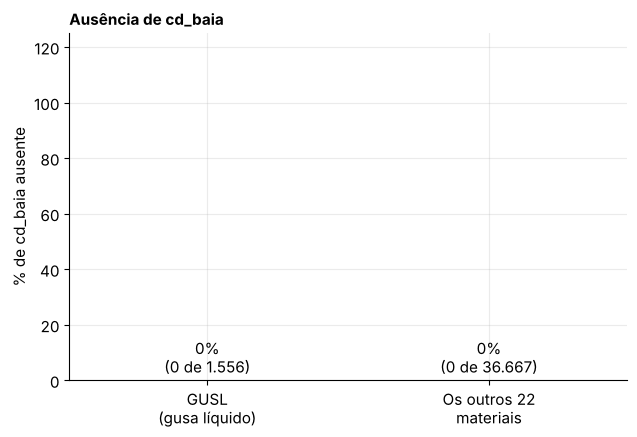

In [38]:
# ---------- GRÁFICO 13 - cd_baia ausente: só no gusa líquido
eh_gusl = base["cd_codigo_material"] == "GUSL"
baia_nula = base["cd_baia"].isnull()
taxa_gusl = baia_nula[eh_gusl].mean() * 100
taxa_outros = baia_nula[~eh_gusl].mean() * 100
# Isso mostra que se, e somente se, o material for GUSL, o cd_baia é nulo.

fig, ax = plt.subplots(figsize=(6.5, 4.5))
nomes = ["GUSL\n(gusa líquido)", "Os outros 22\nmateriais"]
barras = ax.bar(nomes, [taxa_gusl, taxa_outros], color=[VERMELHO, AZUL])
ax.bar_label(barras, labels=[
    f"{pct(taxa_gusl, 0)}\n({br(baia_nula[eh_gusl].sum())} de {br(eh_gusl.sum())})",
    f"{pct(taxa_outros, 0)}\n({br(baia_nula[~eh_gusl].sum())} de {br((~eh_gusl).sum())})",
], padding=3)
ax.set_ylim(0, 125)
ax.set_title(
    "Ausência de cd_baia",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_ylabel("% de cd_baia ausente")
mostrar("06_cd_baia_ausente")

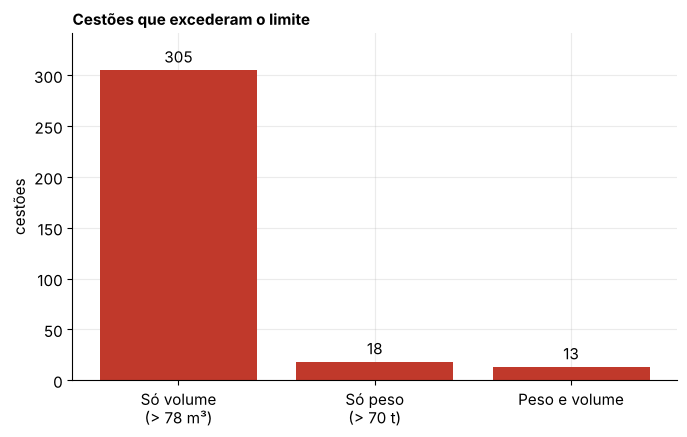

In [39]:
# ---------- GRÁFICO 10 - Cestões que excedem o limite, por motivo
acima_peso = total["peso_t"] > 70
acima_volume = total["volume_m3"] > 78
so_volume = (acima_volume & ~acima_peso).sum()
so_peso = (acima_peso & ~acima_volume).sum()
os_dois = (acima_peso & acima_volume).sum()
excedem = so_volume + so_peso + os_dois

fig, ax = plt.subplots(figsize=(7, 4.5))
nomes = ["Só volume\n(> 78 m³)", "Só peso\n(> 70 t)", "Peso e volume"]
valores = [so_volume, so_peso, os_dois]
barras = ax.bar(nomes, valores, color=VERMELHO)
ax.bar_label(barras, labels=[br(v) for v in valores], padding=3)
ax.set_title(
    "Cestões que excederam o limite",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_ylim(0, max(valores) * 1.12)
ax.set_ylabel("cestões")
mostrar("03_cestoes_que_excedem")

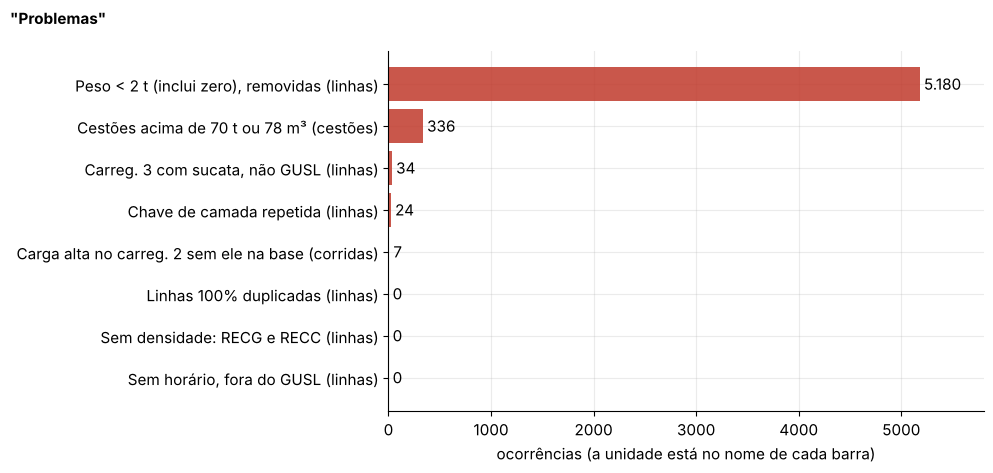

In [40]:
# ---------- GRÁFICO 16 - Resumo dos problemas de qualidade (cada barra tem sua unidade)
flag_c2_sem_c2 = (
    (resposta["is_carga_alta_carregamento_2"] == 1)
    & (~resposta["cd_corrida"].isin(corridas_com_c2))
).sum()

problemas = {
    "Peso < 2 t (inclui zero), removidas (linhas)": (pd.read_csv("../../original_dataset/infos_camadas.csv", na_values=["null"])["qt_peso_carregamento"] < 2000).sum(),
    "Cestões acima de 70 t ou 78 m³ (cestões)": excedem,
    "Sem horário, fora do GUSL (linhas)": (base["dt_hora_consumo"].isnull() & ~eh_gusl).sum(),
    "Carreg. 3 com sucata, não GUSL (linhas)": ((base["nu_carregamento"] == 3) & ~eh_gusl).sum(),
    "Chave de camada repetida (linhas)": base.duplicated(colunas_chave).sum(),
    "Sem densidade: RECG e RECC (linhas)": base["Densidade t/m3"].isnull().sum(),
    "Carga alta no carreg. 2 sem ele na base (corridas)": flag_c2_sem_c2,
    "Linhas 100% duplicadas (linhas)": base.duplicated().sum(),
}
problemas = pd.Series(problemas).sort_values()

fig, ax = plt.subplots(figsize=(10, 4.8))
barras = ax.barh(problemas.index, problemas.values, color=VERMELHO, alpha=0.85)
ax.bar_label(barras, labels=[br(int(v)) for v in problemas.values], padding=3)
ax.set_xlim(0, problemas.max() * 1.12)
fig.suptitle(
    '"Problemas"',
    x=0.01, ha="left", fontweight="bold", fontsize=11,
)
ax.set_xlabel("ocorrências (a unidade está no nome de cada barra)")
mostrar("09_resumo_de_problemas")

Investigação: as 152 linhas "sem_hora_suspeito" (dt_hora_consumo nulo, fora do GUSL) - resumo da investigação que levou à decisão já implementada na Parte A, bloco A.1.

[CONDENSADO] A investigação original (7 células de código) confirmou: 152 linhas sem dt_hora_consumo, fora do GUSL, concentradas em 13 corridas - cada uma com só uma fração das suas linhas sólidas afetada (nunca 100% de uma corrida), ou seja, falha pontual de registro, não um padrão estrutural. O peso dessas linhas é normal (não é zero nem nulo), reforçando que é só a hora que falhou, não o resto do registro. Decisão: estimar a hora pela mediana do carregamento irmão (1 ou 2) da mesma corrida, marcando dt_hora_consumo_estimada = True (implementado na Parte A, bloco A.1).

## ITEM 3 — análise univariada

Cada variável olhada sozinha: taxa de carga alta, carregamentos por tipo, duração das paradas, propriedades dos materiais e número de camadas por cestão.

### GRÁFICO 3 - Taxa de carga alta

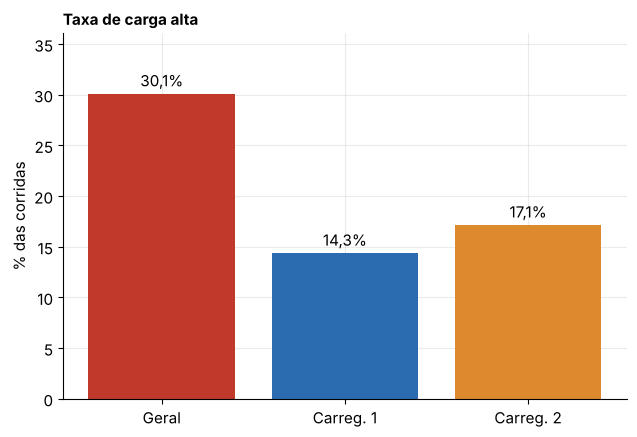

In [41]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nomes = ["Geral", "Carreg. 1", "Carreg. 2"]
taxas = [geral.mean() * 100, c1.mean() * 100, c2.mean() * 100]
barras = ax.bar(nomes, taxas, color=[VERMELHO, AZUL, LARANJA])
ax.bar_label(barras, labels=[pct(t) for t in taxas], padding=3)
ax.set_ylim(0, max(taxas) * 1.2)
ax.set_title(
    "Taxa de carga alta",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_ylabel("% das corridas")
mostrar("01_taxa_de_carga_alta")

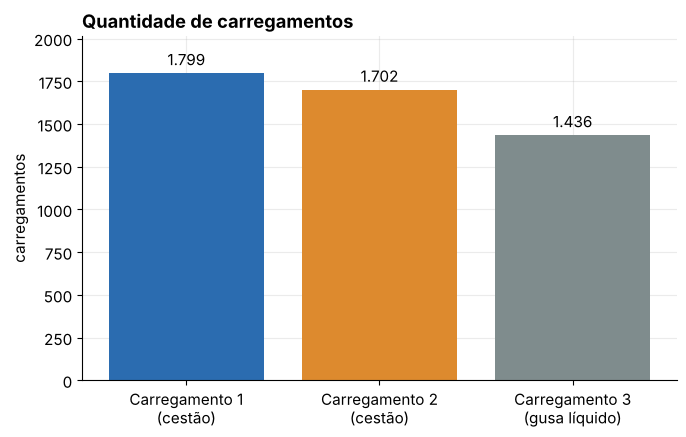

In [42]:
# ---------- GRÁFICO 9 - Carregamentos por tipo
carregamentos = base[["cd_corrida", "nu_carregamento"]].drop_duplicates()
contagem = carregamentos["nu_carregamento"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4.5))
nomes = ["Carregamento 1\n(cestão)", "Carregamento 2\n(cestão)", "Carregamento 3\n(gusa líquido)"]
barras = ax.bar(nomes, contagem.values, color=[AZUL, LARANJA, CINZA])
ax.bar_label(barras, labels=[br(v) for v in contagem.values], padding=3)
ax.set_title(
    "Quantidade de carregamentos",
    loc="left", fontweight="bold",
)
ax.set_ylim(0, contagem.max() * 1.12)
ax.set_ylabel("carregamentos")
mostrar("02_carregamentos_por_tipo")

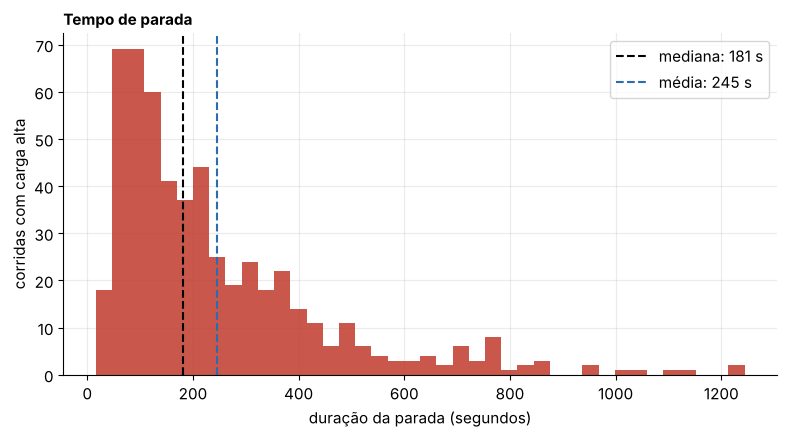

In [43]:
# ---------- GRÁFICO 12 - Duração das paradas por carga alta
paradas = resposta[resposta["is_carga_alta"] == 1]["qt_segundos_parada_carga_alta"]
mediana = paradas.median()
media = paradas.mean()
minutos_total = paradas.sum() / 60

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(paradas, bins=40, color=VERMELHO, alpha=0.85)
ax.axvline(mediana, color="black", linestyle="--", label=f"mediana: {mediana:.0f} s")
ax.axvline(media, color=AZUL, linestyle="--", label=f"média: {media:.0f} s")
ax.set_title(
    "Tempo de parada",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_xlabel("duração da parada (segundos)")
ax.set_ylabel("corridas com carga alta")
ax.legend()
mostrar("05_duracao_das_paradas")

### Dicionário de materiais e número de camadas

In [44]:
import pandas as pd

base = pd.read_csv("base.csv")

In [45]:
# =====================================================================
# Univariada de Energia Elétrica, Densidade e Rendimento Metálico
# Essas 3 colunas são propriedades POR MATERIAL (vêm do dicionário),
# não por linha/corrida - então a análise certa é 1 linha por material,
# não um histograma de 43 mil linhas repetidas.
# =====================================================================
propriedades_material = (
    base[["cd_codigo_material", "Energia Elétrica", "Densidade t/m3", "Rendimento Metálico %"]]
    .drop_duplicates(subset="cd_codigo_material")
    .sort_values("Densidade t/m3")
    .reset_index(drop=True)
)

print("=== Propriedades por material (ordenado por densidade) ===")
print(propriedades_material)

print("\n=== describe() das 3 propriedades ===")
print(propriedades_material[["Energia Elétrica", "Densidade t/m3", "Rendimento Metálico %"]].describe())

props_validas = propriedades_material.dropna(subset=["Densidade t/m3", "Energia Elétrica", "Rendimento Metálico %"])
print("\nMenor densidade:", props_validas.loc[props_validas["Densidade t/m3"].idxmin(), "cd_codigo_material"])
print("Maior densidade:", props_validas.loc[props_validas["Densidade t/m3"].idxmax(), "cd_codigo_material"])
print("Maior consumo de energia:", props_validas.loc[props_validas["Energia Elétrica"].idxmax(), "cd_codigo_material"])
print("Menor consumo de energia:", props_validas.loc[props_validas["Energia Elétrica"].idxmin(), "cd_codigo_material"])
print("Maior rendimento metálico:", props_validas.loc[props_validas["Rendimento Metálico %"].idxmax(), "cd_codigo_material"])
print("Menor rendimento metálico:", props_validas.loc[props_validas["Rendimento Metálico %"].idxmin(), "cd_codigo_material"])

=== Propriedades por material (ordenado por densidade) ===
   cd_codigo_material  Energia Elétrica  Densidade t/m3  Rendimento Metálico %
0                ESPS             343.0            0.40                   0.93
1                RETL             324.0            0.40                   0.94
2                CAVA             405.0            0.49                   0.85
3                MARP             405.0            0.49                   0.85
4                ESBS             343.0            0.50                   0.93
5                PACB             300.0            0.54                   0.83
6                MISM             373.0            0.65                   0.87
7                OXIC             365.0            0.65                   0.88
8                PAEP             343.0            0.70                   0.93
9                PAEB             343.0            0.70                   0.93
10               SHRE             350.0            0.70                 

In [46]:
# =====================================================================
# num_camadas por carregamento (feature nova + univariada)
# =====================================================================
num_camadas = (
    base.groupby(["cd_corrida", "nu_carregamento"])["nu_camada"]
    .nunique()
    .reset_index(name="num_camadas")
)

print("\n=== num_camadas - describe geral ===")
print(num_camadas["num_camadas"].describe())

print("\n=== num_camadas - describe por carregamento (1, 2 ou 3) ===")
print(num_camadas.groupby("nu_carregamento")["num_camadas"].describe())


=== num_camadas - describe geral ===
count    4937.000000
mean        7.737290
std         5.055331
min         1.000000
25%         1.000000
50%         8.000000
75%        13.000000
max        18.000000
Name: num_camadas, dtype: float64

=== num_camadas - describe por carregamento (1, 2 ou 3) ===
                  count       mean       std  min   25%   50%   75%   max
nu_carregamento                                                          
1.0              1799.0  12.920511  1.529399  5.0  12.0  13.0  14.0  18.0
2.0              1702.0   7.863102  2.418222  2.0   6.0   7.0   9.0  15.0
3.0              1436.0   1.094708  0.436265  1.0   1.0   1.0   1.0   9.0


## ITEM 4 — outliers

Regra de negócio (capacidade física: 70t / 78m³) versus critério estatístico (IQR), cruzados entre si.

A regra de negócio (70t / 78m³) continua sendo o critério OFICIAL de "cestão acima da capacidade" - isso não muda, é limite físico. Mas, DENTRO da capacidade, ainda pode ter cestão com peso/volume muito fora do padrão (ex: muito mais leve que a média) - isso é candidato a outlier ESTATÍSTICO, não é a mesma coisa.  OBS: o item "peso = 0" não é tratado aqui - essas camadas foram REMOVIDAS na Parte A (bloco A.3), porque, segundo a EVCOMX, são camadas que estavam na receita mas o gancho não pegou o material (nunca entraram no cestão). Antes elas eram imputadas pela mediana do material, o que estava errado. Pelo mesmo motivo, e com o corte dado pela EVCOMX, saem também todas as camadas abaixo de 2.000 kg.

In [47]:
import pandas as pd
import numpy as np

base = pd.read_csv("base.csv")
for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

base["peso_t"] = base["qt_peso_carregamento"] / 1000
cestoes = base[base["nu_carregamento"].isin([1, 2])].copy()
cestoes["volume_m3"] = cestoes["peso_t"] / cestoes["Densidade t/m3"]

total = cestoes.groupby(["cd_corrida", "nu_carregamento"])[["peso_t", "volume_m3"]].sum().reset_index()

In [48]:
# ---------- Critério de negócio (já existia) ----------
total["acima_capacidade"] = (total["peso_t"] > 70) | (total["volume_m3"] > 78)

In [49]:
# ---------- Critério estatístico (IQR), separado por carregamento ----------
def flag_iqr(grupo, coluna):
    q1, q3 = grupo[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_baixo = q1 - 1.5 * iqr
    limite_alto = q3 + 1.5 * iqr
    return (grupo[coluna] < limite_baixo) | (grupo[coluna] > limite_alto)

total["outlier_peso_iqr"] = total.groupby("nu_carregamento", group_keys=False)["peso_t"].apply(
    lambda s: flag_iqr(total.loc[s.index], "peso_t")
)
total["outlier_volume_iqr"] = total.groupby("nu_carregamento", group_keys=False)["volume_m3"].apply(
    lambda s: flag_iqr(total.loc[s.index], "volume_m3")
)
total["outlier_estatistico"] = total["outlier_peso_iqr"] | total["outlier_volume_iqr"]

In [50]:
# ---------- Conferência: os dois critérios concordam? ----------
print("Acima da capacidade (negócio):", total["acima_capacidade"].sum())
print("Outlier estatístico (IQR):", total["outlier_estatistico"].sum())
print("\nCruzamento (negócio x estatístico):")
print(pd.crosstab(total["acima_capacidade"], total["outlier_estatistico"]))

# Casos interessantes: outlier estatístico MAS dentro da capacidade
# (pode ser erro de registro - cestão com peso muito baixo comparado aos outros)
so_estatistico = total[total["outlier_estatistico"] & ~total["acima_capacidade"]]
print("\nOutlier estatístico, mas dentro da capacidade (investigar):", len(so_estatistico))
print(so_estatistico.groupby("nu_carregamento")[["peso_t", "volume_m3"]].describe().T)

Acima da capacidade (negócio): 336
Outlier estatístico (IQR): 237

Cruzamento (negócio x estatístico):
outlier_estatistico  False  True 
acima_capacidade                 
False                 2947    218
True                   317     19

Outlier estatístico, mas dentro da capacidade (investigar): 218
nu_carregamento        1.0         2.0
peso_t    count   3.000000  215.000000
          mean   34.063333   57.995767
          std     6.279628    3.949880
          min    28.230000   13.900000
          25%    30.740000   56.270000
          50%    33.250000   57.880000
          75%    36.980000   59.615000
          max    40.710000   66.750000
volume_m3 count   3.000000  215.000000
          mean   40.344114   56.352880
          std     8.051646    7.439167
          min    31.804813   16.604286
          25%    36.617178   51.393205
          50%    41.429542   55.773168
          75%    44.613764   60.857463
          max    47.797985   76.143333


In [51]:
mediana_peso = total.groupby("nu_carregamento")["peso_t"].transform("median")

so_estatistico = total[total["outlier_estatistico"] & ~total["acima_capacidade"]].copy()
so_estatistico["tipo"] = np.where(
    so_estatistico["peso_t"] < mediana_peso.loc[so_estatistico.index],
    "muito abaixo da mediana (leve demais)",
    "muito acima da mediana (mas ainda dentro da capacidade)",
)

print(so_estatistico.groupby(["nu_carregamento", "tipo"]).size())

nu_carregamento  tipo                                                   
1.0              muito abaixo da mediana (leve demais)                        3
2.0              muito abaixo da mediana (leve demais)                        1
                 muito acima da mediana (mas ainda dentro da capacidade)    214
dtype: int64


As camadas abaixo de 2.000 kg (peso zero incluído) foram removidas na Parte A (bloco A.3), então o peso de cada cestão agora é só o que de fato entrou. Confira a saída acima: cestões "muito abaixo da mediana" que aparecerem aqui são cestões realmente leves (pouca coisa pegou no gancho), não erro de registro.

## ITEM 5 — features criadas

As features agregadas por cestão que alimentam a análise bivariada e o dataset de modelagem: num_camadas, num_materiais, peso_leve/misto/ pesado, prop_leve.

In [52]:
num_camadas = base.groupby(["cd_corrida", "nu_carregamento"])["nu_camada"].nunique().rename("num_camadas")

# num_materiais: quantos códigos de material DIFERENTES entram no cestão
num_materiais = base.groupby(["cd_corrida", "nu_carregamento"])["cd_codigo_material"].nunique().rename("num_materiais")

peso_por_classe = (
    base.groupby(["cd_corrida", "nu_carregamento", "tp_material"])["peso_t"]
    .sum()
    .unstack("tp_material", fill_value=0)
    .rename(columns={"Leve": "peso_leve", "Misto": "peso_misto", "Pesado": "peso_pesado"})
)

peso_total = base.groupby(["cd_corrida", "nu_carregamento"])["peso_t"].sum().rename("peso_t_total")

features_cestao = pd.concat([num_camadas, num_materiais, peso_por_classe, peso_total], axis=1).reset_index()
features_cestao["prop_leve"] = features_cestao["peso_leve"] / features_cestao["peso_t_total"]


print(features_cestao.head())

  cd_corrida  nu_carregamento  ...  peso_t_total  prop_leve
0      N8707              1.0  ...         56.31   0.217368
1      N8707              2.0  ...         34.99   0.282652
2      N8707              3.0  ...         30.80   0.000000
3      N8731              1.0  ...         55.00   0.272727
4      N8731              2.0  ...         35.42   0.272727

[5 rows x 9 columns]


## ITEM 6 — análise bivariada

Cada feature contra is_carga_alta: boxplot + point-biserial, mapa de correlação (multicolinearidade), peso x volume, posição da camada x tipo de material, volume do cestão 2 com/sem carga alta, carga alta por faixa de peso, e comparação carregamento 1 x 2.

In [53]:
from scipy.stats import pointbiserialr
import matplotlib.pyplot as plt

bivariada = pd.read_csv("dataset_modelagem.csv")
# [AJUSTE P/ ARQUIVO SEPARADO] dt_inicio volta do CSV como texto, não
# como datetime (era datetime só enquanto "cestao" vivia em memória, na
# Parte A) - precisa reconverter pra usar .dt no ITEM 7 (padrões temporais).
bivariada["dt_inicio"] = pd.to_datetime(bivariada["dt_inicio"], utc=True)

features_numericas = ["peso_t_total", "volume_m3_total", "num_camadas", "num_materiais", "peso_leve", "peso_misto", "peso_pesado", "prop_leve"]

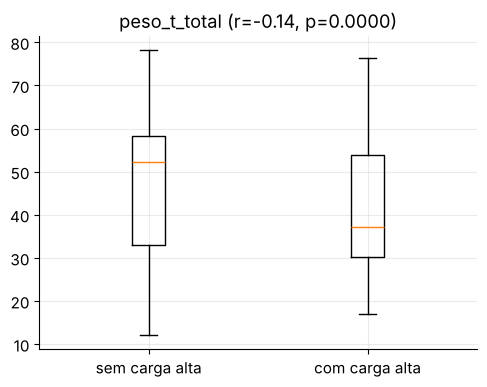

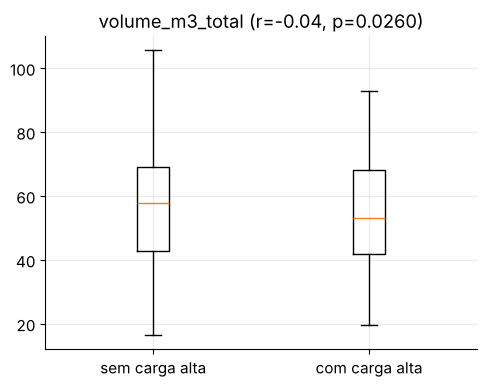

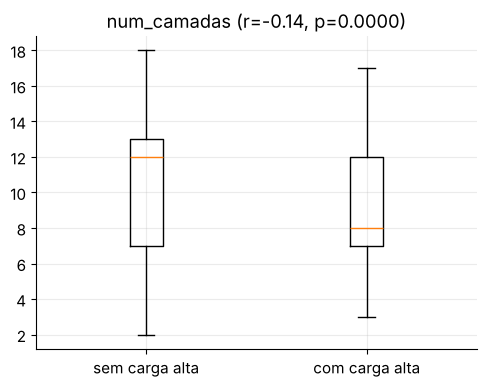

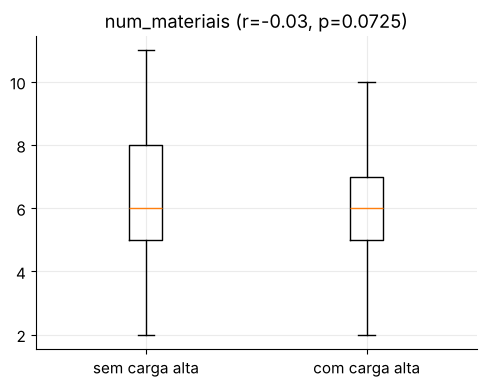

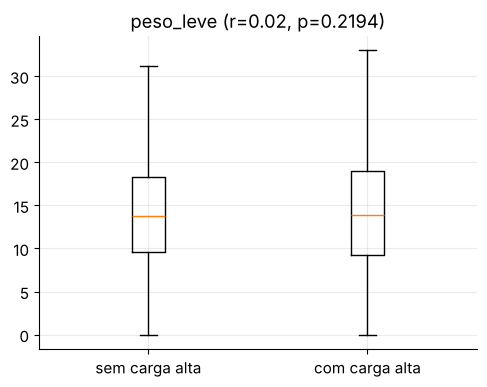

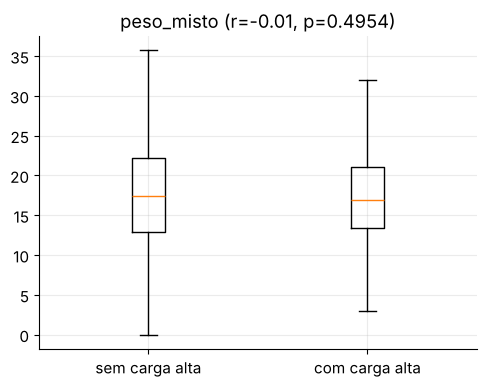

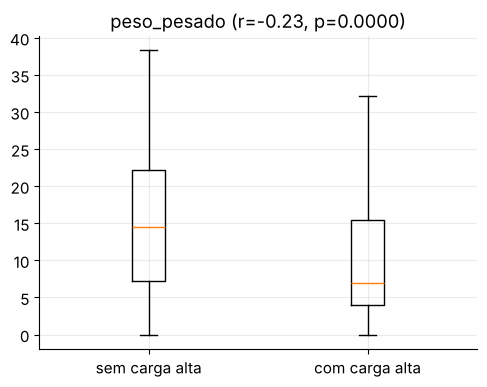

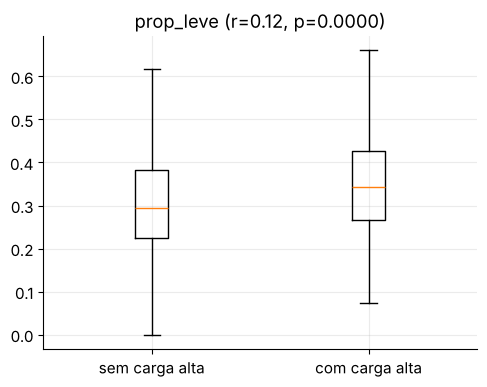

=== Point-biserial: feature x carga_alta ===
           feature      r  p_valor  significativo
6      peso_pesado -0.226   0.0000           True
0     peso_t_total -0.144   0.0000           True
2      num_camadas -0.143   0.0000           True
7        prop_leve  0.120   0.0000           True
1  volume_m3_total -0.038   0.0260           True
3    num_materiais -0.030   0.0725          False
4        peso_leve  0.021   0.2194          False
5       peso_misto -0.012   0.4954          False


In [54]:
# =====================================================================
# Gera o gráfico de: Boxplot e point-biserial, pra cada feature nova
# =====================================================================
resultados = []
for feat in features_numericas:
    r, p = pointbiserialr(bivariada["carga_alta"], bivariada[feat])
    resultados.append({"feature": feat, "r": round(r, 3), "p_valor": round(p, 4), "significativo": p < 0.05})

    plt.figure(figsize=(5, 4))
    plt.boxplot(
        [bivariada[bivariada["carga_alta"] == 0][feat], bivariada[bivariada["carga_alta"] == 1][feat]],
        tick_labels=["sem carga alta", "com carga alta"], showfliers=False,
    )
    plt.title(f"{feat} (r={r:.2f}, p={p:.4f})")
    plt.tight_layout()
    plt.savefig(f"graficos/bivariada_{feat}.png", dpi=130)
    plt.show()

tabela_pb = pd.DataFrame(resultados).sort_values("r", key=abs, ascending=False)
print("=== Point-biserial: feature x carga_alta ===")
print(tabela_pb)

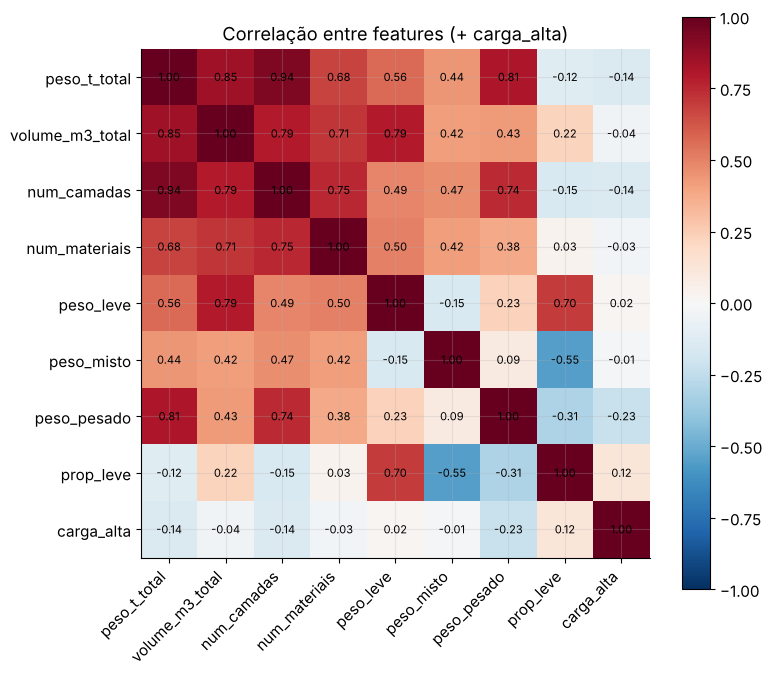


=== Top 10 pares de features mais correlacionadas ===
num_camadas      peso_t_total       0.935935
peso_t_total     num_camadas        0.935935
volume_m3_total  peso_t_total       0.849176
peso_t_total     volume_m3_total    0.849176
                 peso_pesado        0.808058
peso_pesado      peso_t_total       0.808058
num_camadas      volume_m3_total    0.794914
volume_m3_total  num_camadas        0.794914
peso_leve        volume_m3_total    0.791199
volume_m3_total  peso_leve          0.791199
dtype: float64


In [55]:
# =====================================================================
# Heatmap de correlação (multicolinearidade)
# =====================================================================
corr = bivariada[features_numericas + ["carga_alta"]].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
plt.title("Correlação entre features (+ carga_alta)")
plt.tight_layout()
plt.savefig("graficos/heatmap_correlacao.png", dpi=130)
plt.show()

 
print("\n=== Top 10 pares de features mais correlacionadas ===")
pares_top10 = corr.abs().unstack().sort_values(ascending=False)
pares_top10 = pares_top10[pares_top10 < 1.0]   # tira a diagonal (correlação de cada feature com ela mesma)
pares_top10 = pares_top10[~pares_top10.index.duplicated()]
print(pares_top10.head(10))

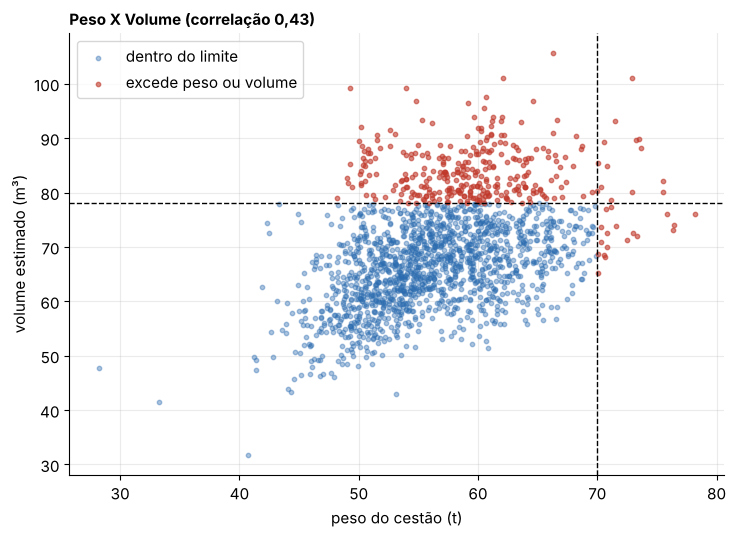

In [56]:
# ---------- GRÁFICO 11 - Peso contra volume (carregamento 1)
c1_pv = total[total["nu_carregamento"] == 1]
correlacao = c1_pv["peso_t"].corr(c1_pv["volume_m3"])
passou = (c1_pv["peso_t"] > 70) | (c1_pv["volume_m3"] > 78)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(c1_pv[~passou]["peso_t"], c1_pv[~passou]["volume_m3"], s=10, alpha=0.4, color=AZUL, label="dentro do limite")
ax.scatter(c1_pv[passou]["peso_t"], c1_pv[passou]["volume_m3"], s=10, alpha=0.6, color=VERMELHO, label="excede peso ou volume")
ax.axvline(70, color="black", linestyle="--", linewidth=1)
ax.axhline(78, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("peso do cestão (t)")
ax.set_ylabel("volume estimado (m³)")
ax.set_title(
    f"Peso X Volume (correlação {correlacao:.2f})".replace(".", ","),
    loc="left", fontweight="bold", fontsize=11,
)
ax.legend()
mostrar("04_peso_contra_volume")

In [57]:
# ---------- Posição relativa de cada camada (usado nos gráficos 14 e 15)
cestoes = cestoes.sort_values(["cd_corrida", "nu_carregamento", "nu_camada"])
# Usa a ORDEM da camada no cestão (1ª, 2ª, ...), não o número nu_camada:
# depois de remover as camadas abaixo de 2.000 kg a numeração fica com buracos.
ordem = cestoes.groupby(["cd_corrida", "nu_carregamento"]).cumcount() + 1
total_camadas = cestoes.groupby(["cd_corrida", "nu_carregamento"])["nu_camada"].transform("size")
cestoes["posicao"] = ordem / total_camadas
cestoes["faixa"] = pd.cut(cestoes["posicao"], [0, 0.3, 0.7, 1.0], labels=["fundo", "meio", "topo"])

# ATENÇÃO (correção da EVCOMX, out/2026): a ordem leve -> pesado -> misto
# -> leve NÃO acontece uma vez só por cestão (leve no fundo, pesado/misto
# no meio, leve no topo). Ela se REPETE em vários ciclos dentro do mesmo
# cestão. Por isso os gráficos 07 e 08 só descrevem onde cada classe cai
# e o que está nas pontas; eles NÃO testam a regra de montagem. Quem
# analisa a regra são os gráficos 12 e 13, logo abaixo.

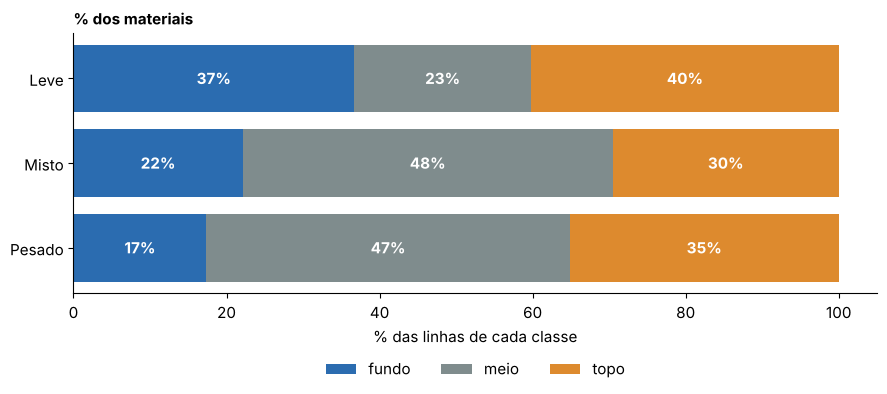

In [58]:
# ---------- GRÁFICO 14 - Onde cada classe de material aparece no cestão
tabela = pd.crosstab(cestoes["tp_material"], cestoes["faixa"], normalize="index") * 100
tabela = tabela.reindex(["Pesado", "Misto", "Leve"])        # Leve fica embaixo no gráfico
leve_meio = tabela.loc["Leve", "meio"]

fig, ax = plt.subplots(figsize=(9, 4.2))
esquerda = np.zeros(len(tabela))
for faixa, cor in [("fundo", AZUL), ("meio", CINZA), ("topo", LARANJA)]:
    ax.barh(tabela.index, tabela[faixa], left=esquerda, color=cor, label=faixa)
    for i, valor in enumerate(tabela[faixa]):
        ax.text(
            esquerda[i] + valor / 2, i, f"{valor:.0f}%".replace(".", ","),
            ha="center", va="center", color="white", fontweight="bold",
        )
    esquerda = esquerda + tabela[faixa].values
ax.set_title(
    "% dos materiais",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_xlabel("% das linhas de cada classe")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.grid(False)
mostrar("07_onde_cada_classe_aparece")

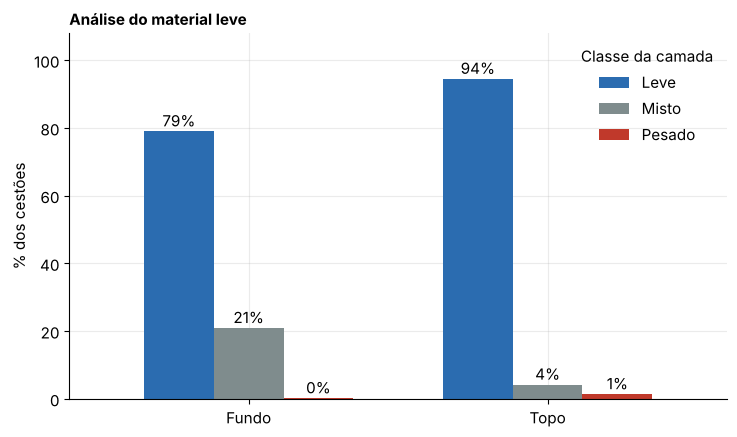

In [59]:
# ---------- GRÁFICO: - Classe da camada de fundo e de topo
classes_cestao = cestoes.groupby(["cd_corrida", "nu_carregamento"])["tp_material"]
fundo = classes_cestao.first().value_counts(normalize=True) * 100
topo = classes_cestao.last().value_counts(normalize=True) * 100
resumo = pd.DataFrame({"Fundo": fundo, "Topo": topo}).fillna(0).T
resumo = resumo.reindex(columns=["Leve", "Misto", "Pesado"]).fillna(0)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
resumo.plot(kind="bar", ax=ax, color=[AZUL, CINZA, VERMELHO], rot=0, width=0.7)
for barra in ax.patches:
    if barra.get_height() > 0:
        ax.text(
            barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.5,
            f"{barra.get_height():.0f}%", ha="center",
        )
ax.set_title(
    "Análise do material leve",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_ylabel("% dos cestões")
ax.set_ylim(0, 108)
ax.legend(title="Classe da camada", frameon=False)
mostrar("08_fundo_e_topo")

In [60]:
# =====================================================================
# Ciclos de montagem (leve -> pesado -> misto -> leve se repetindo)
# =====================================================================
# Cada cestão vira uma sequência de BLOCOS: camadas seguidas da mesma
# classe viram um bloco só (ex.: L L P P M M M P M L -> L P M P M L).
# Como cada ciclo de montagem tem UM bloco de pesado, contamos os ciclos
# pelo número de blocos de pesado ("n_ciclos").
# Obs.: nos dados aparecem tanto L->P->M quanto L->M->P (e o miolo
# costuma alternar P M P M...). Vale confirmar com a EVCOMX se as duas
# ordens são aceitas como "ciclo".
SIGLA = {"Leve": "L", "Pesado": "P", "Misto": "M"}

def blocos(classes):
    """['Leve','Leve','Pesado',...] -> 'LP...' (uma letra por bloco)."""
    letras = [SIGLA[c] for c in classes]
    return "".join(l for i, l in enumerate(letras) if i == 0 or l != letras[i - 1])

seq = (
    cestoes.groupby(["cd_corrida", "nu_carregamento"])["tp_material"]
    .apply(blocos).rename("sequencia_blocos").reset_index()
)
seq["n_blocos"] = seq["sequencia_blocos"].str.len()
seq["n_ciclos"] = seq["sequencia_blocos"].str.count("P")
seq = seq.merge(juntos[["cd_corrida", "nu_carregamento", "carga_alta"]], on=["cd_corrida", "nu_carregamento"])

print("\n=== Sequências de blocos mais comuns ===")
print(seq["sequencia_blocos"].value_counts().head(10))
print("\n=== Transições entre blocos (linha = bloco atual, coluna = próximo) ===")
pares = [(s[i], s[i + 1]) for s in seq["sequencia_blocos"] for i in range(len(s) - 1)]
print(pd.crosstab(pd.Series([a for a, _ in pares], name="atual"),
                  pd.Series([b for _, b in pares], name="próximo")))


=== Sequências de blocos mais comuns ===
sequencia_blocos
LMPML           206
LMPL            142
MPML             96
LMPMPML          77
LMPMPL           69
LML              59
MLMPML           46
LMLPMPMPMPML     46
LMLPML           44
LMPMPMPMPML      41
Name: count, dtype: int64

=== Transições entre blocos (linha = bloco atual, coluna = próximo) ===
próximo     L     M     P
atual                    
L           0  2977  3349
M        3593     0  6696
P        3276  6727     0


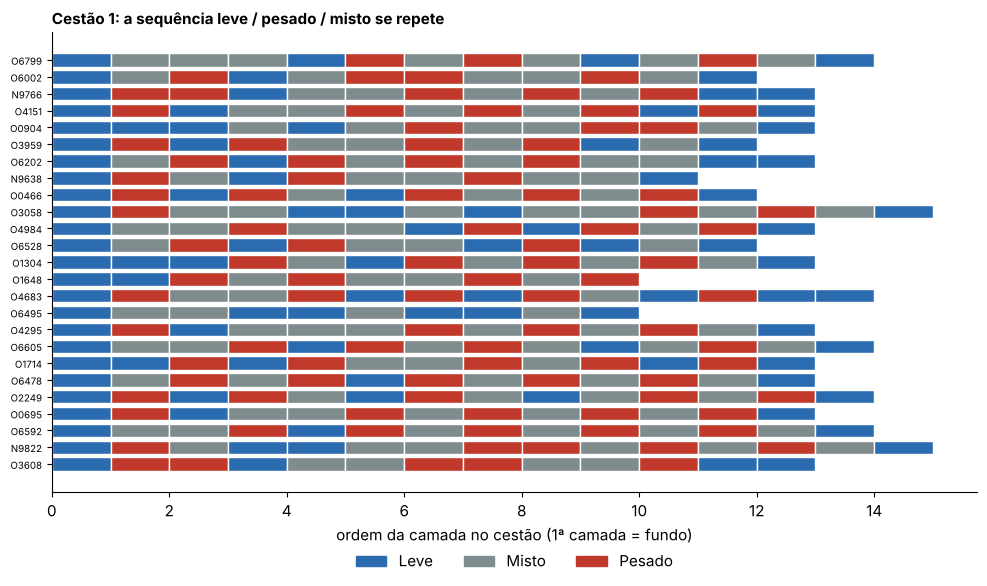

In [61]:
# ---------- GRÁFICO 12 - A sequência real das camadas (amostra de cestões)
COR_CLASSE = {"Leve": AZUL, "Misto": CINZA, "Pesado": VERMELHO}
amostra = (cestoes[cestoes["nu_carregamento"] == 1]
           [["cd_corrida"]].drop_duplicates().sample(25, random_state=42)["cd_corrida"])
fig, ax = plt.subplots(figsize=(10, 6))
for i, corrida in enumerate(amostra):
    camadas_c = cestoes[(cestoes["cd_corrida"] == corrida) & (cestoes["nu_carregamento"] == 1)]
    for j, classe in enumerate(camadas_c["tp_material"]):
        ax.barh(i, 1, left=j, color=COR_CLASSE[classe], edgecolor="white")
ax.set_yticks(range(len(amostra)))
ax.set_yticklabels(amostra, fontsize=7)
ax.set_xlabel("ordem da camada no cestão (1ª camada = fundo)")
ax.set_title("Cestão 1: a sequência leve / pesado / misto se repete", loc="left", fontweight="bold", fontsize=11)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COR_CLASSE.values()],
          labels=list(COR_CLASSE.keys()), loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.grid(False)
mostrar("12_sequencia_das_camadas")


=== Carga alta por número de ciclos ===
   nu_carregamento faixa_ciclos  size      mean
0              1.0       0 ou 1    85  0.423529
1              1.0            2   134  0.201493
2              1.0       3 ou 4  1177  0.140187
3              1.0    5 ou mais   403  0.074442
4              2.0       0 ou 1   979  0.256384
5              2.0            2   325  0.116923
6              2.0       3 ou 4   124  0.064516
7              2.0    5 ou mais   274  0.014599


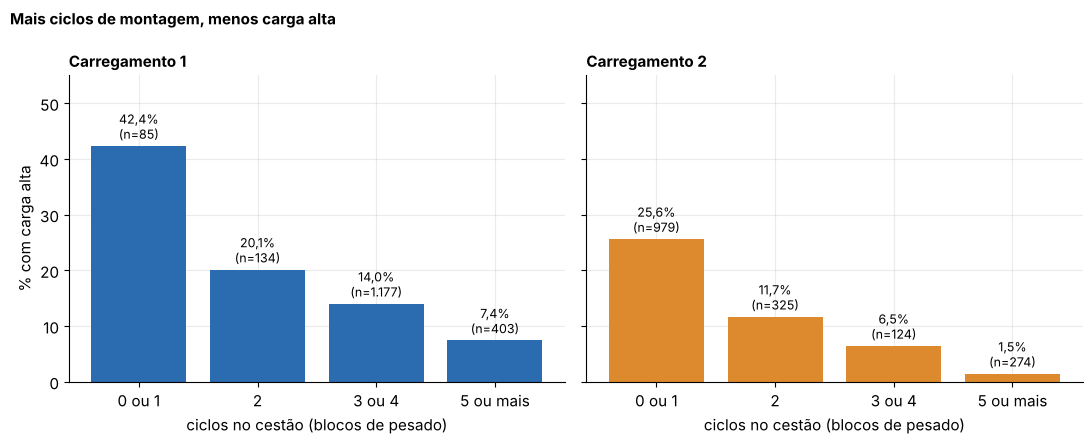

In [62]:
# ---------- GRÁFICO 13 - Carga alta por número de ciclos no cestão
seq["faixa_ciclos"] = pd.cut(seq["n_ciclos"], [-1, 1, 2, 4, 99], labels=["0 ou 1", "2", "3 ou 4", "5 ou mais"])
por_ciclo = (seq.groupby(["nu_carregamento", "faixa_ciclos"], observed=False)["carga_alta"]
             .agg(["size", "mean"]).reset_index())
print("\n=== Carga alta por número de ciclos ===")
print(por_ciclo)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, carreg, cor in zip(axes, [1, 2], [AZUL, LARANJA]):
    dados = por_ciclo[por_ciclo["nu_carregamento"] == carreg]
    barras = ax.bar(dados["faixa_ciclos"].astype(str), dados["mean"] * 100, color=cor)
    ax.bar_label(barras, labels=[f"{pct(m * 100)}\n(n={br(int(n))})" for n, m in zip(dados["size"], dados["mean"])],
                 padding=3, fontsize=9)
    ax.set_title(f"Carregamento {carreg}", loc="left", fontweight="bold", fontsize=11)
    ax.set_xlabel("ciclos no cestão (blocos de pesado)")
axes[0].set_ylabel("% com carga alta")
axes[0].set_ylim(0, por_ciclo["mean"].max() * 100 * 1.3)
fig.suptitle("Mais ciclos de montagem, menos carga alta", x=0.01, ha="left", fontweight="bold", fontsize=11)
mostrar("13_carga_alta_por_ciclos")

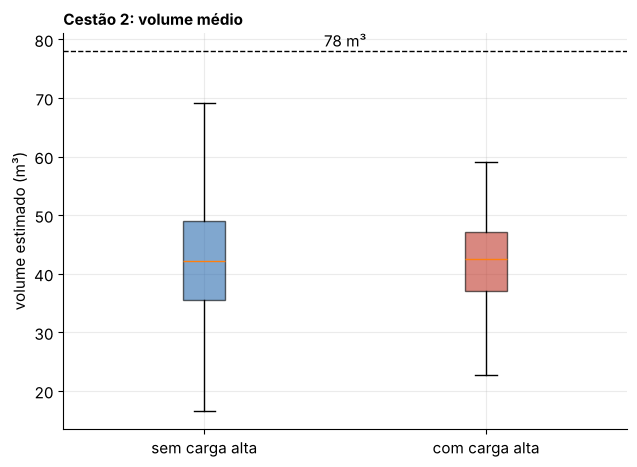

In [63]:
# ---------- GRÁFICO: - Volume do cestão 2: com e sem carga alta
c2_box = juntos[juntos["nu_carregamento"] == 2]
sem = c2_box[c2_box["carga_alta"] == 0]["volume_m3"]
com = c2_box[c2_box["carga_alta"] == 1]["volume_m3"]

fig, ax = plt.subplots(figsize=(6.5, 4.8))
caixas = ax.boxplot(
    [sem, com], tick_labels=["sem carga alta", "com carga alta"],
    patch_artist=True, showfliers=False,
)
for caixa, cor in zip(caixas["boxes"], [AZUL, VERMELHO]):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.6)
ax.axhline(78, color="black", linestyle="--", linewidth=1)
ax.text(1.5, 78.8, "78 m³", ha="center")
ax.set_title(
    "Cestão 2: volume médio",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_ylabel("volume estimado (m³)")
mostrar("10_volume_cestao2_com_e_sem_carga_alta")

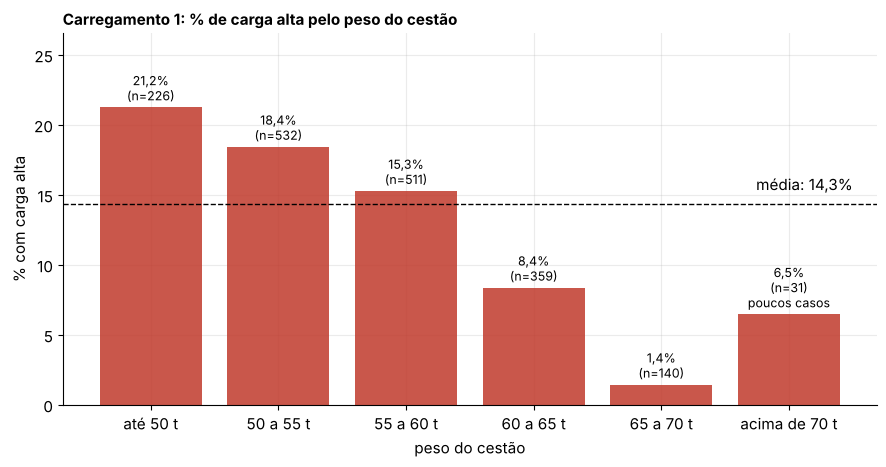

In [64]:
# ---------- GRÁFICO 18 - Carga alta por faixa de peso (carregamento 1) - PRÉVIA
c1j = juntos[juntos["nu_carregamento"] == 1].copy()
c1j["faixa_peso"] = pd.cut(c1j["peso_t"], [0, 50, 55, 60, 65, 70, np.inf], labels=["até 50 t", "50 a 55 t", "55 a 60 t", "60 a 65 t", "65 a 70 t", "acima de 70 t"])
por_faixa = c1j.groupby("faixa_peso", observed=True)["carga_alta"].agg(["size", "mean"])
media_geral = c1j["carga_alta"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.8))
barras = ax.bar(por_faixa.index.astype(str), por_faixa["mean"] * 100, color=VERMELHO, alpha=0.85)
rotulos = []
for n, m in zip(por_faixa["size"], por_faixa["mean"]):
    aviso = "\npoucos casos" if n < 100 else ""
    rotulos.append(f"{pct(m * 100)}\n(n={br(n)}){aviso}")
ax.bar_label(barras, labels=rotulos, padding=3, fontsize=9)
ax.axhline(media_geral, color="black", linestyle="--", linewidth=1)
ax.text(len(por_faixa) - 0.5, media_geral + 1, f"média: {pct(media_geral)}", ha="right")
ax.set_ylim(0, por_faixa["mean"].max() * 100 * 1.25)
ax.set_title(
    "Carregamento 1: % de carga alta pelo peso do cestão",
    loc="left", fontweight="bold", fontsize=11,
)
ax.set_xlabel("peso do cestão")
ax.set_ylabel("% com carga alta")
mostrar("11_carga_alta_por_faixa_de_peso")

In [65]:
# =====================================================================
# Carregamento 1 x 2
# =====================================================================
print("\n=== Taxa de carga alta por carregamento ===")
print(bivariada.groupby("nu_carregamento")["carga_alta"].agg(["mean", "count"]))


=== Taxa de carga alta por carregamento ===
                     mean  count
nu_carregamento                 
1.0              0.143413   1799
2.0              0.176851   1702


## ITEM 7 — padrões temporais

Taxa de carga alta por turno e por dia da semana.

[NOTA] O turno usado abaixo (madrugada/manhã/tarde/noite, pd.cut) é DIFERENTE do turno oficial do Guia da EVCOMX (Turno A 06h-14h, B 14h-22h, C 22h-06h) - decidir se troca pra bater com o guia ou se mantém e justifica a escolha na apresentação.

In [66]:
dt_local = bivariada["dt_inicio"].dt.tz_convert("America/Sao_Paulo")
bivariada["turno"] = pd.cut(dt_local.dt.hour, [-1, 6, 12, 18, 24], labels=["madrugada", "manha", "tarde", "noite"])
bivariada["dia_semana"] = dt_local.dt.day_name()

print("\n=== Taxa de carga alta por turno ===")
print(bivariada.groupby("turno")["carga_alta"].agg(["mean", "count"]))
print("\n=== Taxa de carga alta por dia da semana ===")
print(bivariada.groupby("dia_semana")["carga_alta"].agg(["mean", "count"]))


=== Taxa de carga alta por turno ===
               mean  count
turno                     
madrugada  0.174740   1156
manha      0.117709    943
tarde      0.164336    572
noite      0.183133    830

=== Taxa de carga alta por dia da semana ===
                mean  count
dia_semana                 
Friday      0.147950    561
Monday      0.195294    425
Saturday    0.110924    595
Sunday      0.126957    575
Thursday    0.176344    465
Tuesday     0.180995    442
Wednesday   0.210046    438


## ITEM 8 — dicionário de materiais

Scatter Densidade x Energia Elétrica (colorido por Rendimento Metálico) e verificação numérica da regra leve/pesado do guia.

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

base = pd.read_csv("base.csv")
for col in ["Densidade t/m3", "Rendimento Metálico %"]:
    if not pd.api.types.is_numeric_dtype(base[col]):
        base[col] = base[col].str.replace(",", ".").astype(float)

In [68]:
# ---------- Propriedades únicas por material (exclui RECG/RECC, sem dados) ----------
materiais = (
    base[["cd_codigo_material", "tp_material", "Densidade t/m3", "Energia Elétrica", "Rendimento Metálico %"]]
    .drop_duplicates(subset="cd_codigo_material")
    .dropna(subset=["Densidade t/m3", "Energia Elétrica", "Rendimento Metálico %"])
)

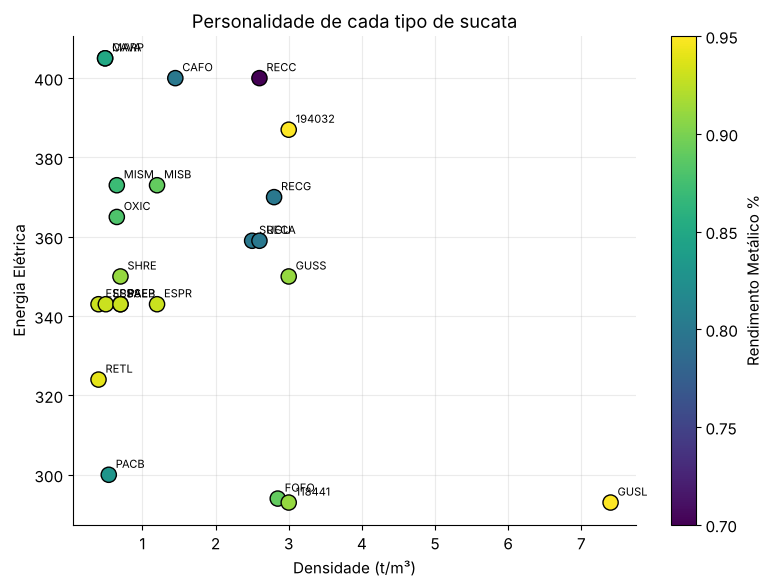

In [69]:
# ---------- Scatter: Densidade x Energia, cor = Rendimento (Guia, seção 3.2) ----------
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(materiais["Densidade t/m3"], materiais["Energia Elétrica"],
                 c=materiais["Rendimento Metálico %"], cmap="viridis", s=120, edgecolor="black")
for _, row in materiais.iterrows():
    ax.annotate(row["cd_codigo_material"], (row["Densidade t/m3"], row["Energia Elétrica"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.colorbar(sc, label="Rendimento Metálico %")
ax.set_xlabel("Densidade (t/m³)")
ax.set_ylabel("Energia Elétrica")
ax.set_title("Personalidade de cada tipo de sucata")
plt.tight_layout()
plt.savefig("graficos/scatter_materiais.png", dpi=130)
plt.show()

In [70]:
# ---------- Checando a regra do Guia (seção 3.3) ----------
leve = materiais[materiais["tp_material"] == "Leve"]
pesado = materiais[materiais["tp_material"] == "Pesado"]

print("Leve: exceções com densidade >= 0.55 ->", (leve["Densidade t/m3"] >= 0.55).sum())
print(leve[leve["Densidade t/m3"] >= 0.55][["cd_codigo_material", "Densidade t/m3"]])
print("\nLeve: exceções com rendimento <= 0.90 ->", (leve["Rendimento Metálico %"] <= 0.90).sum())
print(leve[leve["Rendimento Metálico %"] <= 0.90][["cd_codigo_material", "Rendimento Metálico %"]])

print("\nPesado: exceções com densidade <= 2.50 ->", (pesado["Densidade t/m3"] <= 2.50).sum())
print(pesado[pesado["Densidade t/m3"] <= 2.50][["cd_codigo_material", "Densidade t/m3"]])

Leve: exceções com densidade >= 0.55 -> 1
  cd_codigo_material  Densidade t/m3
4               SHRE             0.7

Leve: exceções com rendimento <= 0.90 -> 3
     cd_codigo_material  Rendimento Metálico %
13                 PACB                   0.83
33                 CAVA                   0.85
5162               MARP                   0.85

Pesado: exceções com densidade <= 2.50 -> 1
  cd_codigo_material  Densidade t/m3
1               SUGU             2.5


In [71]:
# ---------- Insumos CAL/COQUE: já resolvido, só documentando ----------
print("\nOcorrências de CAL/COQUE no base.csv:",
      base["cd_codigo_material"].isin(["7071955", "8800022", "7071940"]).sum())


Ocorrências de CAL/COQUE no base.csv: 0


## ITEM 9 — os sinais que o modelo oficial usa

O modelo oficial do projeto (média de 5 Gradient Boosting, 121 features; ver src/selecao_algoritmos/) se apoia muito em três informações que NÃO estão na receita do cestão. Antes de modelar, vale ver nos dados brutos que elas existem e o tamanho delas: 1. histórico do forno: carga alta puxa carga alta; 2. gusa líquida (carregamento 3): corridas sem gusa quase não dão carga alta; 3. resultado do cestão 1: quando ele dá carga alta, o cestão 2 da mesma corrida dá MENOS. (Antes, o modelo era uma Random Forest com 6 features, quase só de receita + histórico.)

Taxa de carga alta da corrida conforme o nº de cargas altas nas 5 anteriores:
          mean  size
ca_ult5             
0.0      0.143   617
1.0      0.209   464
2.0      0.312   285
3.0      0.489   174
4.0      0.632   133
5.0      0.769   121
Depois de uma corrida com carga alta: 55%; depois de uma sem: 19%

Taxa de carga alta da corrida por quantidade de gusa líquida:
             mean  size
faixa_gusa             
sem gusa    0.041   363
até 30 t    0.194   144
30–35 t     0.339   679
35–40 t     0.450   418
> 40 t      0.408   191

Taxa de carga alta do cestão 2 conforme o cestão 1 da mesma corrida:
                               mean  size
is_carga_alta_carregamento_1             
0                             0.184  1541
1                             0.097   258


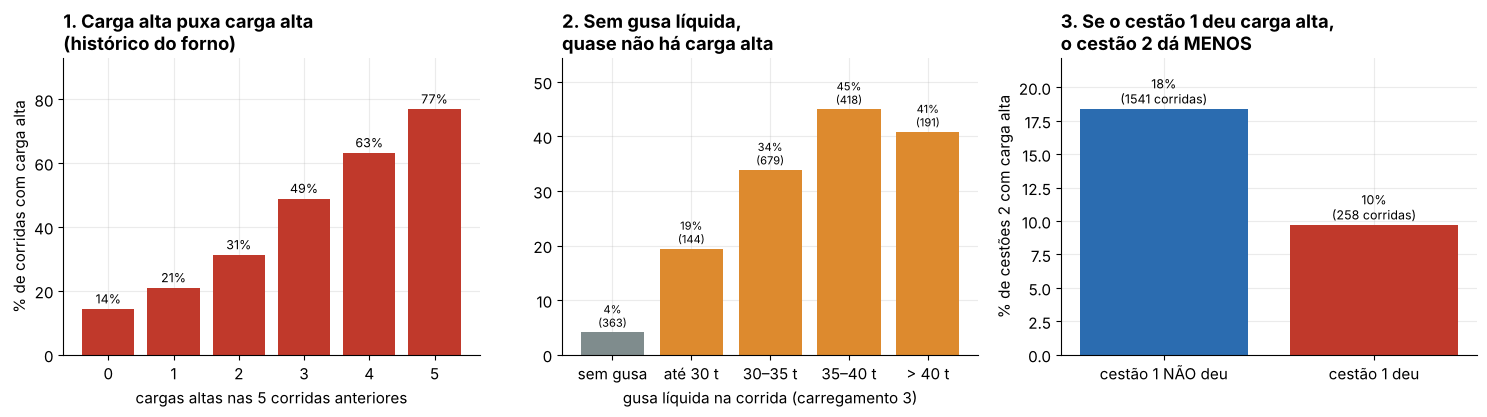

In [72]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("graficos", exist_ok=True)
AZUL, VERMELHO, CINZA, LARANJA = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e"
base = pd.read_csv("base.csv")
resposta = pd.read_csv("../../original_dataset/VariavelResposta.csv")
base["dt_hora_consumo"] = pd.to_datetime(base["dt_hora_consumo"], utc=True, format="mixed")

# ordem das corridas pelo início do cestão 1 (só corridas com receita registrada)
inicio = base[base.nu_carregamento == 1].groupby("cd_corrida")["dt_hora_consumo"].min()
corr = resposta.set_index("cd_corrida").loc[resposta.cd_corrida.isin(inicio.index).values].copy()
corr["inicio"] = inicio.reindex(corr.index)
corr = corr.sort_values("inicio")

# 1) histórico: nº de cargas altas nas 5 corridas ANTERIORES (shift(1): nunca a atual)
corr["ca_ult5"] = corr["is_carga_alta"].shift(1).rolling(5, min_periods=5).sum()
hist = corr.dropna(subset=["ca_ult5"]).groupby("ca_ult5")["is_carga_alta"].agg(["mean", "size"])
print("Taxa de carga alta da corrida conforme o nº de cargas altas nas 5 anteriores:")
print(hist.round(3))
apos = corr["is_carga_alta"].shift(1)
print(f"Depois de uma corrida com carga alta: {corr.is_carga_alta[apos == 1].mean():.0%}; "
      f"depois de uma sem: {corr.is_carga_alta[apos == 0].mean():.0%}")

# 2) gusa líquida da corrida
gusa = base[(base.nu_carregamento == 3) & (base.cd_codigo_material == "GUSL")].groupby("cd_corrida")["qt_peso_carregamento"].sum() / 1000
corr["gusa_t"] = gusa.reindex(corr.index).fillna(0)
corr["faixa_gusa"] = pd.cut(corr.gusa_t, [-0.1, 0.1, 30, 35, 40, 100], labels=["sem gusa", "até 30 t", "30–35 t", "35–40 t", "> 40 t"])
g_gusa = corr.groupby("faixa_gusa", observed=True)["is_carga_alta"].agg(["mean", "size"])
print("\nTaxa de carga alta da corrida por quantidade de gusa líquida:")
print(g_gusa.round(3))

# 3) cestão 1 → cestão 2
c2 = corr.dropna(subset=["is_carga_alta_carregamento_2"])
c12 = c2.groupby("is_carga_alta_carregamento_1")["is_carga_alta_carregamento_2"].agg(["mean", "size"])
print("\nTaxa de carga alta do cestão 2 conforme o cestão 1 da mesma corrida:")
print(c12.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
b = axes[0].bar(hist.index.astype(int).astype(str), 100 * hist["mean"], color=VERMELHO)
axes[0].bar_label(b, labels=[f"{100 * v:.0f}%" for v in hist["mean"]], padding=2, fontsize=9)
axes[0].set_xlabel("cargas altas nas 5 corridas anteriores"); axes[0].set_ylabel("% de corridas com carga alta")
axes[0].set_title("1. Carga alta puxa carga alta\n(histórico do forno)", loc="left", fontweight="bold")
b = axes[1].bar(g_gusa.index.astype(str), 100 * g_gusa["mean"], color=[CINZA] + [LARANJA] * (len(g_gusa) - 1))
axes[1].bar_label(b, labels=[f"{100 * v:.0f}%\n({n})" for v, n in zip(g_gusa["mean"], g_gusa["size"])], padding=2, fontsize=8)
axes[1].set_xlabel("gusa líquida na corrida (carregamento 3)")
axes[1].set_title("2. Sem gusa líquida,\nquase não há carga alta", loc="left", fontweight="bold")
b = axes[2].bar(["cestão 1 NÃO deu", "cestão 1 deu"], 100 * c12["mean"].values, color=[AZUL, VERMELHO])
axes[2].bar_label(b, labels=[f"{100 * v:.0f}%\n({n} corridas)" for v, n in zip(c12["mean"], c12["size"])], padding=2, fontsize=9)
axes[2].set_ylabel("% de cestões 2 com carga alta")
axes[2].set_title("3. Se o cestão 1 deu carga alta,\no cestão 2 dá MENOS", loc="left", fontweight="bold")
for ax in axes:
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.tight_layout()
plt.savefig("graficos/14_sinais_do_modelo_oficial.png", dpi=130)
plt.show()